# How a simulated particle breaks and what replaces it, step by step on the laboratory jaw, and where the method stops working

**Question:** How does the simulation decide that a particle breaks and what replaces it, and where does the method stop working on the laboratory jaw of Barrios et al. (2020)?

- **Level:** 2, the method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 90 minutes (the live runs add about four minutes)

## Objectives

By the end of this notebook you can:

- follow one sphere from the contact force it feels, through the energy it takes in, the damage it accumulates, the t10 of its break and the sizes of its progeny, to its replacement in the bed, calling the package's own function at each step and checking the first two against a hand calculation;
- say what the replacement conserves and what bounds it, and why the run is stopped by a limit on the overlap of the spheres;
- read the steady window of a batch and the standard error of its mean power, and say why a window of three strokes gives no error on its trend;
- state what happens to the largest overlap as the batch grows and at each rung of the product's overlap ladder, with the committed runs of the three feeds beside the live ones, and say where the method stops working on this jaw;
- set up the machine, the ore and the feed of your own crusher and know what to read in the output.

## Setup

This notebook calls the published package `crushdem` 0.6.0 for every step, in the same environment as notebook 01. Install it with its compiled kernels and the pinned numerical stack:

```bash
pip install "crushdem[jit]==0.6.0" numba==0.68.1 llvmlite==0.50.0 numpy==2.4.6 matplotlib==3.11.2
```

The cell prints the versions and imports the contact and breakage functions that the steps use, the laboratory jaw case, the comparison protocol and the product's operating points.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import contextlib
import importlib.metadata as md
import io
import json
import math
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('crushdem', 'numba', 'llvmlite', 'numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public functions only: the notebook defines no method of its own
from crushdem import ContactTable, OverlapError, ParticleState, PairParams, Simulation, comparison, stable_time_step
from crushdem.breakage import BreakageBounds, breakage_probability, damage_increment, draw_progeny
from crushdem.breakage import BETA_PARAMS, incomplete_beta, median_fracture_energy, progeny_curve, t10_of_energy
from crushdem.cases import barrios2020 as case
from crushdem.core.materials import effective_modulus, energy_share, tsuji_alpha
from crushdem.core.state import rayleigh_time_step
from crushdem.machines import barrios_contact_table
from pipeline.dem import points as P
plt.rcParams.update({"figure.figsize": (8.6, 3.8), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

crushdem 0.6.0
numba 0.68.1
llvmlite 0.50.0
numpy 2.4.6
matplotlib 3.11.2


## Data

Two sources. The ore and its single-particle tests are the package's: the 30 breakage forces per size class of Fig. 6b of Barrios et al. (2020), https://doi.org/10.3390/min10080717, CC BY 4.0, digitised and shipped as package data; `case.paper_ore` derives the ore from them. The second source is the committed document of the product's bake, `data/derived/dem/jaw-lab.json` (catalog row `dem-run`), written by `data-pipeline/run.py dem`, which runs this same case at full size (6 kg) for the three feeds and keeps every attempt. The notebook reads it only for the run control and for the attempts and per-stroke series of section 4's comparison; every live number is computed here.

The cell reads the document and prints its state and the run control it records.

In [2]:
# The committed document of the full-size runs, read here only for the run control and the attempts of section 4
doc = json.loads((ROOT / "data/derived/dem/jaw-lab.json").read_text(encoding="utf-8"))
settings = doc["settings"]
final = {pt["feed_class"]: pt["simulation"] for pt in doc["points"]}
print("document state:", doc["state"], "|", "crushdem", doc["package"]["version"], doc["package"]["backend"])
print("overlap ladder:", settings["overlap_ladder"], "| stall after", settings["stall_strokes"],
      "strokes | seed", doc["seed"], "| batch", settings["batch_kg"], "kg")

document state: partial | crushdem 0.6.0 numba
overlap ladder: [0.3, 0.5] | stall after 40 strokes | seed 1 | batch 6.0 kg


## Method

A batch is a loop of strokes, and each stroke is a loop of steps; the replacement rule follows Cleary and Sinnott (2015) and Barrios et al. (2020), with the strength of a sphere of Tavares (2022). At every step the engine finds the contacts, evaluates the forces of the contact law, moves the spheres and the plate, and adds up the work each sphere's contacts do while loading it. Every 50 steps the host takes that work, ends the events that have stopped, decides which spheres break and replaces them. The eight steps below take that cycle apart in the order of its causes: the contact, the strength of a sphere, the damage, the t10, the progeny, the replacement, the stroke loop and the window that turns strokes into the averages to compare with a measurement.

### Step 1: the contact and the time step

Two ore spheres of radii $R_i$ and $R_j$ press into each other by the overlap $\delta$ and push apart with the Hertz force

$$F_n = \tfrac{4}{3}\,E^{*}\sqrt{R^{*}}\;\delta^{3/2}, \qquad E^{*} = \left(\frac{1-\nu_i^2}{E_i} + \frac{1-\nu_j^2}{E_j}\right)^{-1}, \qquad R^{*} = \frac{R_iR_j}{R_i+R_j},$$

with the Young moduli $E$ and Poisson ratios $\nu$ of the two bodies. The step of the integration may not exceed a fraction $f$ of the Rayleigh time, the time a stress wave takes to cross the smallest sphere (as the documentation of fix check/timestep/gran states it),

$$\Delta t = f\,\Delta t_R, \qquad \Delta t_R = \frac{\pi R\sqrt{\rho/G}}{0.1631\,\nu + 0.8766},$$

with $R$, $\rho$, $G$ and $\nu$ the radius, density, shear modulus and Poisson ratio of that sphere, and $f = 0.1$ in this product. The cell computes $E^{*}$ of two ore spheres by hand and through the package, the force at three overlaps, the damping constant of the ore-ore restitution, and the time step the run uses.

In [3]:
# Step 1: the contact of two 10 mm ore spheres, by hand and through the package, and the stable time step of the run
ore_mat = case.ORE_MATERIAL
e_star = effective_modulus(ore_mat, ore_mat)
by_hand = 1.0 / (2.0 * (1.0 - ore_mat.poisson**2) / ore_mat.youngs_modulus)
r_star = 0.005 * 0.005 / (0.005 + 0.005)
print(f"E* package {e_star:.4g} Pa, by hand {by_hand:.4g} Pa, R* = {r_star * 1e3:.2f} mm")
for overlap_um in (5.0, 20.0, 80.0):
    delta = overlap_um * 1e-6
    print(f"overlap {overlap_um:5.1f} um: F_n = {4.0 / 3.0 * e_star * math.sqrt(r_star) * delta ** 1.5:8.2f} N")
print(f"damping constant at restitution 0.35: alpha = {tsuji_alpha(0.35):.4f}")
table = barrios_contact_table()
probe = ParticleState.from_arrays([[0, 0, 0]], [0.5 * P.MINIMUM_SPHERE_MM * 1e-3], table, material=[0])
dt = stable_time_step(probe, table, 0.1)
dt_rayleigh = rayleigh_time_step(0.5 * P.MINIMUM_SPHERE_MM * 1e-3, ore_mat)
print(f"time step of the run {dt:.3e} s = {dt / dt_rayleigh:.2f} of the Rayleigh time {dt_rayleigh:.3e} s")

E* package 1.333e+08 Pa, by hand 1.333e+08 Pa, R* = 2.50 mm
overlap   5.0 um: F_n =     0.10 N
overlap  20.0 um: F_n =     0.80 N
overlap  80.0 um: F_n =     6.36 N
damping constant at restitution 0.35: alpha = 0.7096
time step of the run 3.559e-06 s = 0.10 of the Rayleigh time 3.559e-05 s


The effective modulus of two ore spheres is 1.333e+08 Pa by hand and through the package, with an effective radius of 2.50 mm for two spheres of 10 mm. The force grows as the overlap to the power 3/2: 0.10 N at 5 micrometres, 0.80 N at 20 and 6.36 N at 80, so quadrupling the overlap multiplies the force by 8. The damping constant of Tsuji et al. (1992) for a restitution of 0.35 is 0.7096. The time step of 3.559e-06 s is a tenth of the Rayleigh time of the 4 mm sphere, 3.559e-05 s, because the minimum sphere the product keeps sets the stiffest, fastest contact, and every other sphere is then well inside the limit.

### Step 2: the strength of a sphere

The paper gives no breakage parameter of its ore, only the breakage force of 30 particles in each of three size classes (Fig. 6b, page 7). The package turns each class's median force $F_{50}$ into the specific energy a sphere of that size absorbs when two steel plates squeeze it to that force, through the Hertz contact of the two materials,

$$\delta = \left(\frac{3F}{4E^{*}\sqrt{R}}\right)^{2/3}, \qquad E_{50} = \frac{2\,e\cdot\tfrac{2}{5}F_{50}\,\delta}{m}, \qquad E_{50}(d) = E_\infty\left[1 + \left(\frac{d_0}{d}\right)^{\phi}\right],$$

with $R$ the sphere radius, $E^{*}$ the effective modulus of ore against steel, $e$ the share of the contact work that goes into the ore (Tavares, 2022, equation 9), $m$ the mass of the sphere and the factor 2 for the two contacts. The size effect is then fitted through the two coarse classes with the exponent $\phi$ fixed at the value of the gneiss of Tavares (2022), and the variance $\sigma^2$ of the lognormal law of the previous notebook is taken from the spread of the 30 forces, capped at 1.2. The cell prints the three classes, the fit and the data value of the variance.

In [4]:
# Step 2: the ore the package derives from the single-particle tests of the paper, and its size effect
ore, derivation = case.paper_ore("A", seed=1)
print("class         median force [N]   sigma of ln F   mapped E50 [J/kg]")
for name, stats in derivation["classes"].items():
    e50_class = derivation["e50_j_kg"][name]
    print(f"{name:>10s} {stats['empirical_median_force_n']:18.1f} {stats['sigma_ln_force']:15.3f} {e50_class:19.1f}")
print(f"E_inf = {ore.e_inf:.2f} J/kg, d0 = {ore.d0 * 1e3:.2f} mm, phi = {ore.phi} (fixed),",
      f"sigma^2 = {ore.variance} (data value {derivation['variance_from_data']:.2f})")
print(f"misfit of the finest class in ln E50: {derivation['fit_residual_ln'][2]:.2f}")

class         median force [N]   sigma of ln F   mapped E50 [J/kg]
     63/53             4831.1           1.029                26.6
 31.5/26.5             1965.6           1.053                58.2
 16.0/13.2             1701.9           1.075               451.1
E_inf = 13.84 J/kg, d0 = 55.02 mm, phi = 1.82 (fixed), sigma^2 = 1.2 (data value 3.08)
misfit of the finest class in ln E50: -0.98


The median forces are 4831.1, 1965.6 and 1701.9 N for the three classes and map to 26.6, 58.2 and 451.1 J/kg: the finest class, whose force hardly drops below the middle one's, is by far the strongest per unit of mass because the energy goes as the force to the power 5/3 and the mass as the size cubed. The fit through the two coarse classes gives $E_\infty$ = 13.84 J/kg and $d_0$ = 55.02 mm, and it misses the finest class by -0.98 in the logarithm, a factor of 2.7: the fit puts the median at 168.6 J/kg for a 14.6 mm sphere where the data map 451.1. The variance from the spread of the forces is 3.08, above the 1.2 allowed by the literature range that the product takes as its cap. Two assumptions of the derivation therefore carry the finest feed, the fixed exponent and the extrapolation below 29 mm, and the package's record says so.

Figure 1 draws the size effect with the three mapped classes, and the probability of breaking against the event energy for spheres of 57.5, 29.0 and 14.6 mm.

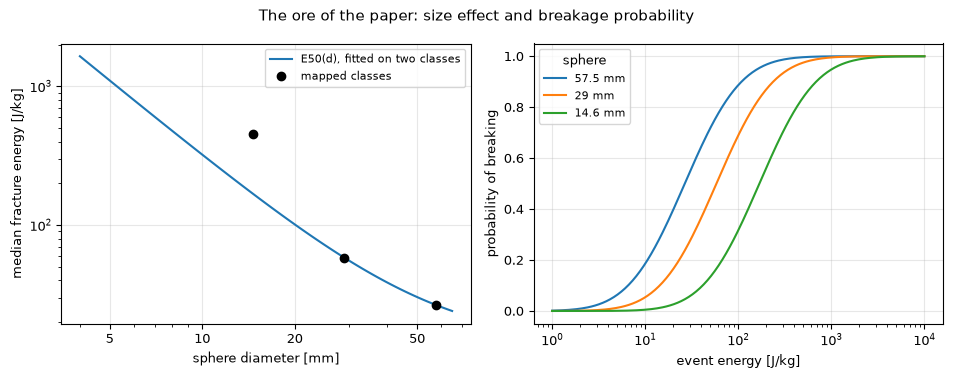

In [5]:
# Figure 1: the size effect E50(d) with the three mapped classes, and the breakage probability of three sizes
d_grid = np.logspace(math.log10(0.004), math.log10(0.065), 80)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
axes[0].loglog(d_grid * 1e3, median_fracture_energy(d_grid, ore), "-", label="E50(d), fitted on two classes")
mean_d = [case.SIZE_CLASS_MEAN_M[k] * 1e3 for k in derivation["classes"]]
axes[0].loglog(mean_d, [derivation["e50_j_kg"][k] for k in derivation["classes"]], "ko", label="mapped classes")
axes[0].set_xlabel("sphere diameter [mm]")
axes[0].set_xticks([5, 10, 20, 50])
axes[0].xaxis.set_major_formatter(plt.ScalarFormatter())
axes[0].xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylabel("median fracture energy [J/kg]")
axes[0].legend(fontsize=8)
energy = np.logspace(0, 4, 200)
for d_mm in (57.5, 29.0, 14.6):
    axes[1].semilogx(energy, breakage_probability(energy, d_mm * 1e-3, ore), label=f"{d_mm:g} mm")
axes[1].set_xlabel("event energy [J/kg]")
axes[1].set_ylabel("probability of breaking")
axes[1].legend(title="sphere", fontsize=8)
fig.suptitle("The ore of the paper: size effect and breakage probability")
fig.tight_layout()
plt.show()

Reading figure 1. On the left the size effect rises toward small sizes, passes through the two coarse classes by construction and lies below the finest one, which is the misfit above. On the right the probability of breaking is a broad S curve on a logarithmic axis: with a variance of 1.2 the energy that breaks a sphere with probability 0.1 and the one that breaks it with probability 0.9 differ by more than an order of magnitude, and the curve of the 14.6 mm sphere lies more than six times to the right of the 57.5 mm one. The figure does not show the effect of damage, which moves a sphere along its own curve, and it does not show any measurement of the paper's ore beyond the three medians.

### Step 3: damage below the fracture energy

An event whose energy $e\,E_k$ stays below the fracture energy $E$ does not break the sphere but weakens it. Tavares (2022, equations 11 and 12) writes the fracture energy after the event as $E' = E\,(1 - D)$, with the damage $D$ the smallest root of

$$D = \left[\frac{2\gamma}{2\gamma - 5D + 5}\;\frac{e\,E_k}{E}\right]^{2\gamma/5},$$

where $\gamma$ is the damage coefficient (3.5 here, an assumption of the product taken from the middle of the range the paper gives) and $e\,E_k/E$ the event energy as a share of the fracture energy. `damage_increment` solves it by bracketing. The cell prints the damage of single events at 10, 30, 50 and 80 percent of the fracture energy, and then hits one sphere of 14.6 mm over and over with events of 30 percent of its original fracture energy, applying $E' = E(1-D)$ after each, until the event energy reaches what is left.

In [6]:
# Step 3: the damage of one event below the fracture energy, and a sphere hit again and again by events of 30
# percent of it
ratios = np.linspace(0.01, 0.99, 99)
damage = damage_increment(ratios * 100.0, 100.0, ore.gamma)
d_at = {r: float(damage_increment(r * 100.0, 100.0, ore.gamma)) for r in (0.1, 0.3, 0.5, 0.8)}
print("damage D of one event at 10, 30, 50 and 80 percent of the fracture energy:",
      {k: round(v, 4) for k, v in d_at.items()})
e_frac = float(median_fracture_energy(0.0146, ore))
event, current, history = 0.3 * e_frac, e_frac, []
while event < current and len(history) < 30:
    increment = float(damage_increment(event, current, ore.gamma))
    current *= 1.0 - increment
    history.append((increment, current))
print(f"sphere of 14.6 mm, fracture energy {e_frac:.1f} J/kg, events of {event:.1f} J/kg")
print(f"the sphere breaks at event {len(history) + 1};",
      "its fracture energy before each event [J/kg]:",
      [round(e_frac, 1)] + [round(c, 1) for _, c in history])

damage D of one event at 10, 30, 50 and 80 percent of the fracture energy: {0.1: 0.0189, 0.3: 0.0921, 0.5: 0.2014, 0.8: 0.4652}
sphere of 14.6 mm, fracture energy 168.6 J/kg, events of 50.6 J/kg
the sphere breaks at event 8; its fracture energy before each event [J/kg]: [168.6, 153.1, 136.8, 119.6, 101.1, 80.7, 57.0, 23.3]


The damage grows faster than the event: 0.0189 at 10 percent, 0.0921 at 30, 0.2014 at 50 and 0.4652 at 80 percent of the fracture energy. The sphere of 14.6 mm, with a fracture energy of 168.6 J/kg, hit by events of 50.6 J/kg, a third of what it needs, loses fracture energy at every event, 168.6, 153.1, 136.8, 119.6, 101.1, 80.7, 57.0 and 23.3 J/kg, and breaks at the eighth event, when the 50.6 J/kg of the event exceed the 23.3 J/kg that remain. This is the mechanism by which a bed of spheres that none of its contacts can break at once still crushes: the spheres lodged in the bed are loaded many times, and each load takes some of their strength away.

### Step 4: t10 from the energy of the event

When a sphere breaks, the size of its pieces follows from one number, the percentage $t_{10}$ of its mass that ends up below a tenth of its size. Tavares (2022, equation 20) gives it as a saturating function of the energy the sphere took in:

$$t_{10} = A\left[1 - \exp\!\left(-\,b'\,\frac{e\,E_k}{E_{50}(d)}\right)\right],$$

with $A$ the largest $t_{10}$ of a single event (59.7 percent), $b'$ a dimensionless constant (0.025), $e\,E_k$ the specific energy of the event and $E_{50}(d)$ the median fracture energy of the sphere's size, used here for the median of the particles that broke (an assumption stated in the package's documentation). The cell evaluates it for a coarse and a fine sphere at three absolute energies, through the package and by hand.

In [7]:
# Step 4: t10 from the energy of the event, by hand and through the package, for two spheres at three energies
print("sphere [mm]  E50 [J/kg]  e Ek [J/kg]  t10 package [%]  t10 by hand [%]")
for d_mm in (57.5, 14.6):
    e50 = float(median_fracture_energy(d_mm * 1e-3, ore))
    for event_energy in (25.0, 100.0, 400.0):
        t10_pkg = float(t10_of_energy(event_energy, d_mm * 1e-3, ore))
        t10_hand = ore.a_max * (1.0 - math.exp(-ore.b_prime * event_energy / e50))
        print(f"{d_mm:11.1f} {e50:11.1f} {event_energy:12.0f} {t10_pkg:15.3f} {t10_hand:15.3f}")

sphere [mm]  E50 [J/kg]  e Ek [J/kg]  t10 package [%]  t10 by hand [%]
       57.5        26.6           25           1.386           1.386
       57.5        26.6          100           5.354           5.354
       57.5        26.6          400          18.703          18.703
       14.6       168.6           25           0.221           0.221
       14.6       168.6          100           0.879           0.879
       14.6       168.6          400           3.438           3.438


Package and hand calculation agree to three decimals. At the same energy the coarse sphere breaks much finer than the fine one: 100 J/kg gives a $t_{10}$ of 5.354 percent for the 57.5 mm sphere, whose median fracture energy is 26.6 J/kg, and 0.879 percent for the 14.6 mm one, whose median is 168.6 J/kg, because what counts is the energy as a multiple of the size's own median. The strong, fine spheres of the 16/13.2 mm feed therefore break into few large pieces, and the weak, coarse spheres of the 63/52 mm feed break into many.

### Step 5: the progeny

From $t_{10}$ the package builds the whole cumulative size distribution of the pieces. The mass passing a fraction $1/n$ of the parent size, $t_n$, is a regularised incomplete beta function (Tavares, 2022, equation 16):

$$t_n = 100\; I_{t_{10}/100}\!\left(\alpha_n,\,\beta_n\right), \qquad I_x(a,b) = \frac{\int_0^x s^{a-1}(1-s)^{b-1}\,ds}{B(a,b)},$$

with $(\alpha_n, \beta_n)$ the tabulated parameters for $n$ = 1.2, 1.5, 2, 4, 25, 50 and 75 (Table 2 of the paper), $B$ the beta function and $s$ the integration variable. Step 5a checks the package's continued-fraction evaluation against an independent Gauss-Legendre integral of the density, after the substitution $u = s^{a}$ that removes the singularity at 0. Step 5b draws 400 parents of 60 mm with $t_{10}$ = 15 percent through `draw_progeny`, which turns the mass distribution into spheres: it draws pieces from the number distribution that carries the mass distribution, keeps the largest ones that fit in the parent's mass, and sends the mass below the 4 mm minimum sphere to the fines.

In [8]:
# Step 5a: equation 16, t_n = 100 I_x(alpha_n, beta_n), against an independent Gauss-Legendre integral of the beta
# density
t10_value = 15.0
x = t10_value / 100.0
nodes, weights = np.polynomial.legendre.leggauss(64)
print("n    alpha_n  beta_n   package [%]   independent integral [%]")
for n in (2.0, 4.0, 25.0):
    a, b = BETA_PARAMS[n]
    # the substitution u = t^a removes the singularity of the density at 0
    top = x**a
    u = 0.5 * top * (nodes + 1.0)
    integrand = (1.0 - u ** (1.0 / a)) ** (b - 1.0)
    integral = 0.5 * top * np.sum(weights * integrand) / a / (math.gamma(a) * math.gamma(b) / math.gamma(a + b))
    print(f"{n:4.0f} {a:9.3f} {b:7.3f} {100 * incomplete_beta(a, b, x):12.3f} {100 * integral:22.3f}")

n    alpha_n  beta_n   package [%]   independent integral [%]
   2     0.959   5.780       62.616                 62.616
   4     1.105   2.619       30.377                 30.377
  25     0.981   0.524        8.519                  8.519


The package and the independent integral agree to three decimals at all three sizes: 62.616, 30.377 and 8.519 percent for $n$ = 2, 4 and 25 at a $t_{10}$ of 15 percent. The next cell compares the law with what 400 sampled parents deliver.

In [9]:
# Step 5b: 400 parents of 60 mm drawn with t10 = 15 percent, against the curve of equation 16
curve = progeny_curve(t10_value)
rng = np.random.default_rng(1)
d_parent = 0.06
mass = 2700.0 * math.pi / 6.0 * d_parent**3
drawn = [draw_progeny(mass, d_parent, 2700.0, t10_value, ore.min_diameter, rng) for _ in range(400)]
print("size ratio n   curve [%]   mean of 400 parents [%]")
for n in (1.2, 2.0, 4.0):
    below = []
    for p in drawn:
        pieces = 2700.0 * math.pi / 6.0 * np.array(p.diameters) ** 3
        below.append(pieces[np.array(p.diameters) < d_parent / n].sum() + p.fines_kg)
    print(f"{n:15.1f} {curve.cumulative(1.0 / n):10.2f} {100 * np.mean(below) / mass:24.2f}")
fines = 100 * np.mean([p.fines_kg for p in drawn]) / mass
law_fines = curve.cumulative(ore.min_diameter / d_parent)
print(f"fines below the minimum size, curve {law_fines:.2f} %, drawn {fines:.2f} %")
print(f"pieces per parent {np.mean([len(p.diameters) for p in drawn]):.1f}")

size ratio n   curve [%]   mean of 400 parents [%]
            1.2      94.17                    94.73
            2.0      62.62                    60.39
            4.0      30.38                    26.81
fines below the minimum size, curve 11.68 %, drawn 11.68 %
pieces per parent 73.5


The fines of the sampled parents equal the law's, 11.68 percent, because the package fixes them by construction. At the coarser sizes the sample falls below the law: 60.39 against 62.62 percent at half the parent size and 26.81 against 30.38 percent at a quarter, a shortfall of up to 3.6 points. A parent holds a finite mass, about 73.5 pieces here, and a piece larger than the mass left cannot be drawn, so the largest pieces are under-represented; the package's own tests bound this departure at 4 points. Nothing in the sampled curve says the law is wrong: it says what a finite parent can follow.

### Step 6: the replacement and its bounds

The parent is removed and its pieces are written into free slots of the particle pool with the parent's velocity and spin. Two conservation facts and one bound make the replacement safe. Mass: the pieces and the fines carry the parent's mass, $\sum_k m_k + m_{\text{fines}} = m_{\text{parent}}$, to a relative residual bound of $10^{-9}$. Momentum: the pieces keep the parent's velocity, so momentum is conserved and kinetic energy can only fall. The bound: the pieces of a heavy parent cannot all lie inside the parent's volume, so they start inside it and are pushed apart by a position-only relaxation until every overlap is under $10^{-3}$ of the smaller radius, and the Hertz energy left in those overlaps, the energy the replacement injects, must not exceed a share of the energy the parent absorbed,

$$E_{\text{inj}} \le 0.1\; m\,e\,E_k, \qquad E_{\text{inj}} = \sum \tfrac{8}{15}E^{*}\sqrt{R^{*}}\,\delta^{5/2},$$

with $m\,e\,E_k$ the absorbed energy of the parent and the sum over the overlaps that remain. A parent whose pieces do not fit in the free slots (the particle cap) or cannot be placed within the bound is not broken at this service, and the event waits. The cell builds the laboratory jaw, runs two strokes of 0.5 kg of the 16/13.2 mm feed with the log of the breakage manager and prints the bounds, the first five events and the totals.

In [10]:
# Step 6: the replacement of a parent, in two live strokes: the manager's event log and its bounds
machine, sim = case.build(ore, 0.5, 6.0, 1, 800, 0.3, "numba", feed_class="16/13.2")
sim.run_cycles(2, machine.period_s)
events = sim.breakage.events()
report = sim.breakage_report()
print("bounds:", sim.bounds)
print("event  parent [mm]  energy [J/kg]  t10 [%]  progeny  fines [g]  mass residual [kg]  injected/absorbed")
for k in range(5):
    ev = {name: values[k] for name, values in events.items()}
    print(f"{k + 1:5d} {ev['diameter_m'] * 1e3:12.2f} {ev['specific_energy_j_kg']:13.1f} {ev['t10_percent']:8.3f}",
          f"{ev['n_progeny']:8d} {ev['fines_kg'] * 1e3:10.3f} {ev['mass_residual_kg']:19.1e}",
          f"{ev['injected_energy_j'] / ev['absorbed_energy_j']:18.2e}")
print(f"{report['n_events']} events in two strokes;",
      f"largest injected share of the absorbed energy {report['max_injected_fraction']:.2e};",
      f"largest mass residual ratio {report['max_mass_residual_ratio']:.1e}")
print(f"deferred by the particle cap {report['n_deferred_cap']},",
      f"deferred by placement {report['n_deferred_placement']}")

bounds: BreakageBounds(mass_tolerance=1e-09, max_injection_fraction=0.1, max_relax_overlap=0.001, max_relax_iterations=400, min_damage_energy_fraction=0.001)
event  parent [mm]  energy [J/kg]  t10 [%]  progeny  fines [g]  mass residual [kg]  injected/absorbed
    1        15.87          76.0    0.768        2      0.074             2.7e-20           6.11e-08
    2        15.40          84.7    0.814        3      0.076             1.0e-18           1.47e-07
    3        14.59          43.8    0.386        3      0.032             9.7e-19           5.26e-07
    4        13.43         422.8    3.165        6      0.274            -1.6e-19           7.11e-10
    5        13.98         729.1    5.710        6      0.532             1.1e-18           1.29e-09
12 events in two strokes; largest injected share of the absorbed energy 4.93e-03; largest mass residual ratio 5.1e-16
deferred by the particle cap 0, deferred by placement 1


The first events are weak: parents of 13.43 to 15.87 mm take 43.8 to 729.1 J/kg, give $t_{10}$ between 0.386 and 5.710 percent and break into 2 to 6 pieces, most of the mass in two or three large spheres and a few grams of fines. Mass closes to a residual of about $10^{-18}$ kg per event, 5.1e-16 of the parent in the worst case against the bound of $10^{-9}$, and the energy injected by the placements is at most 4.93e-03 of what the parent absorbed, against the bound of 0.1. None of the 12 events of the two strokes was deferred by the particle cap and one was deferred by placement, so the bounds act as designed. A coarse sphere does not shatter at its first break: it splits and each piece is loaded again, which is why the batch needs strokes.

The same cell construction shows the guard that stops a run. `case.build` takes the overlap limit as a fraction of the smaller radius, and any step whose largest overlap passes it raises `OverlapError`. The next cell sets it to 0.05, far tighter than the 0.3 of the contact model, so that the error appears within a stroke.

In [11]:
# The overlap guard: the same strokes with a limit of 0.05 of the smaller radius stop with the package's own error
machine, tight = case.build(ore, 0.5, 6.0, 1, 800, 0.05, "numba", feed_class="16/13.2")
try:
    tight.run_cycles(3, machine.period_s)
except OverlapError as error:
    print("OverlapError:", error)
print(f"simulated time when it stopped {tight.time:.3f} s,",
      f"stroke period {machine.period_s:.3f} s")

OverlapError: overlap of 0.051 of the smaller radius at sphere 17 exceeds the limit 0.050 (step 73400); the run is unstable or the time step too large
simulated time when it stopped 0.261 s, stroke period 0.167 s


The error names the overlap (0.051 of the smaller radius against the limit of 0.050), the sphere and the step, and the run stops 0.261 s into the simulation, in its second stroke of 0.167 s. The message says "the run is unstable or the time step too large", which is the only diagnosis the check can make: it cannot tell a jammed bed from a local event such as a sphere pinched at a plate edge. The product uses the package's default of 0.3 first and, if a run stops there, tries 0.5 once; section 4 reads what that ladder did at full size.

### Step 7: the stroke loop, its completion and its stall

`run_attempt` runs one stroke at a time and records the mass held, the mass passed, the mean power of the swing plate and the largest overlap. It stops by one of four rules, tested after each stroke in this order: the batch is complete when no sphere is held and the pending feed is at most half the mass of the smallest sphere of the feed class; a run is stalled when the mass passed has not grown by 0.1 percent of the batch for 40 strokes (the number the product sets in its run control); the stroke limit; and the wall-time limit. An `OverlapError` ends the attempt with its own status. The cell runs 1 kg of the 16/13.2 mm feed at the first rung of the ladder, with 1200 slots for particles.

In [12]:
# Step 7: the stroke loop with its completion and stall rules: 1 kg of the 16/13.2 mm feed at the first rung of
# the ladder
stall = settings["stall_strokes"]
with contextlib.redirect_stdout(io.StringIO()):
    run = case.run_attempt(ore, 1.0, 6.0, 1, 1200, 0.3, "numba", 14, 900.0, stall, feed_class="16/13.2")
half_sphere = case.one_sphere_mass_kg("16/13.2")
print("status:", run["status"], "|", run["strokes"], "strokes |", f"{run['sim_time_s']:.2f} s simulated")
print(f"completion needs nothing held and at most {half_sphere * 1e3:.2f} g pending")
print("stroke  held  passed [kg]  plate power [W]  largest overlap")
for row in run["series"]:
    print(f"{row['stroke']:6d} {row['n_hold']:6d} {row['passed_kg']:11.3f}",
          f"{row['swing_plate_w']:15.1f} {row['max_overlap']:16.3f}")

status: complete | 10 strokes | 1.67 s simulated
completion needs nothing held and at most 1.63 g pending
stroke  held  passed [kg]  plate power [W]  largest overlap
     1    225       0.000             0.0            0.012
     2    229       0.120            61.2            0.182
     3    203       0.234           100.8            0.264
     4    195       0.343            36.4            0.264
     5    151       0.455            44.7            0.231
     6    134       0.574            74.7            0.242
     7     97       0.700            68.6            0.242
     8     68       0.833           115.3            0.283
     9     31       0.946            17.1            0.283
    10      0       1.000            -7.0            0.142


The batch of 1 kg completes in 10 strokes, 1.67 s of simulated time. Stroke 1 only feeds: 225 spheres are held and nothing has passed. From stroke 2 the plate works, with a mean power between 17.1 and 115.3 W, and the mass passed rises by about a tenth of the batch per stroke, 0.120, 0.234, 0.343 kg, until stroke 10 passes the last of it, 1.000 kg, with no sphere held. The power of the last stroke is slightly negative, -7.0 W, because the plate no longer pushes a bed and its mean is the work against the last grains and its own motion. The completion threshold of 1.63 g is half the mass of a sphere of 13.2 mm. In strokes 2 to 9 the largest overlap stays between 0.182 and 0.283, below the 0.3 limit, so this batch completes where the same feed at 6 kg will not, as section 4 shows.

### Step 8: the steady window and the standard error

A batch has a start-up, a body and an emptying, and only the body is comparable with the mean power of a continuous machine. The protocol of the package fixes the window by mass, not by a count of strokes: with $m_k$ the cumulative mass passed after stroke $k$ and $M$ the total,

$$k_a = \min\{k : m_k \ge 0.25\,M\}, \qquad k_b = \max\{k : m_k \le 0.75\,M\}, \qquad \text{window} = \text{strokes } k_a + 1 \text{ to } k_b,$$

with at least 6 strokes in the run and at least 3 between the two marks, otherwise there is no window and no number. The strokes are not independent samples, since a bed loaded in one stroke is loaded in the next, so the standard error of the mean power uses the lag-1 autocorrelation $r_1$ of the strokes (Bayley and Hammersley, 1946):

$$n_{\text{eff}} = n\,\frac{1 - r_1}{1 + r_1}, \qquad \text{SE} = \frac{s}{\sqrt{\min(n,\,n_{\text{eff}})}},$$

with $n$ the strokes of the window and $s$ the standard deviation of their power; a negative $r_1$ earns no credit. Step 8a applies the functions to the live run above, and step 8b to the committed 6 kg run of the 63/52 mm feed, whose window is long enough to say something.

In [13]:
# Step 8a: the steady window by mass and the standard error with the lag-1 autocorrelation, on the live run of 1 kg
live = comparison.window_statistics(run["series"], 1.0 / 6.0)
window, power, trend = live["window"], live["power"], live["trend"]
print(f"window: strokes {window.first_stroke} to {window.last_stroke} ({window.n} strokes),",
      "from 25 to 75 percent of the mass passed")
print(f"plate power: mean {power['mean']:.1f} W, sd {power['sd']:.1f} W, r1 = {power['r1']:.3f},",
      f"n_eff = {power['n_eff']:.2f}, strokes used {power['n_used']:.2f},",
      f"standard error {power['se']:.1f} W")
print(f"trend of the power: {trend['slope']:.2f} +/- {trend['standard_error']:.2f} W/stroke,",
      f"stationary: {trend['stationary']}")

window: strokes 5 to 7 (3 strokes), from 25 to 75 percent of the mass passed
plate power: mean 62.7 W, sd 15.8 W, r1 = -0.287, n_eff = 5.41, strokes used 3.00, standard error 9.2 W
trend of the power: 11.96 +/- 0.00 W/stroke, stationary: False


The live window is strokes 5 to 7, three strokes, with a mean power of 62.7 W and a standard deviation of 15.8 W. Their lag-1 autocorrelation is -0.287, so $n_{\text{eff}}$ is 5.41 but the three strokes are used, and the standard error is 9.2 W. The trend of the power over the window reads 11.96 W per stroke with a standard error of 0.00 and "stationary: False". That zero is not a measurement: a straight line through three points has one degree of freedom left and the package reports no error below four points, so the flag is undetermined, not negative. A window this short can state a mean and cannot state whether the power drifts.

In [14]:
# Step 8b: the same functions on the committed 6 kg run of the 63/52 mm feed, whose window holds 29 strokes
big = final["63/52"]["series"]
columns = {"stroke": big["stroke"], "t_s": big["t_s"], "passed_kg": big["passed_kg"]}
columns["swing_plate_w"] = big["plate_power_w"]
stats = comparison.window_statistics(columns, 1.0 / 6.0)
window, power, trend, flow = stats["window"], stats["power"], stats["trend"], stats["throughput"]
print(f"window: strokes {window.first_stroke} to {window.last_stroke} ({window.n} strokes)")
print(f"plate power: mean {power['mean']:.1f} W, sd {power['sd']:.1f} W, r1 = {power['r1']:.3f},",
      f"n_eff = {power['n_eff']:.2f}, strokes used {power['n_used']:.2f},",
      f"standard error {power['se']:.1f} W")
print(f"trend: {trend['slope']:.2f} +/- {trend['standard_error']:.2f} W/stroke,",
      f"stationary: {trend['stationary']}")
print(f"throughput {flow['mean']:.0f} kg/h, standard error {flow['se']:.0f} kg/h;",
      f"specific energy {stats['specific_energy_j_kg']:.0f} J/kg")

window: strokes 37 to 65 (29 strokes)
plate power: mean 300.9 W, sd 133.9 W, r1 = -0.301, n_eff = 54.02, strokes used 29.00, standard error 24.9 W
trend: -1.45 +/- 3.01 W/stroke, stationary: True
throughput 2167 kg/h, standard error 50 kg/h; specific energy 500 J/kg


Figure 2 draws the plate power of every stroke of that committed run with its window, and the cumulative mass with the 25 and 75 percent marks that define it.

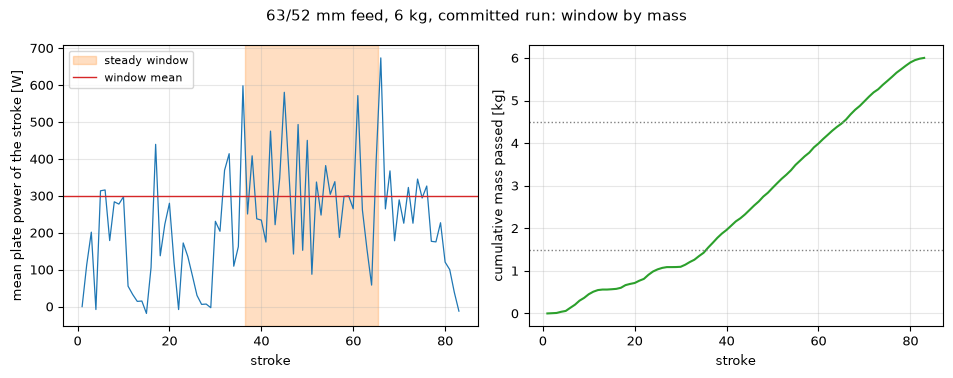

In [15]:
# Figure 2: the plate power of every stroke of the full-size run with its steady window, and the mass passed with
# the 25 and 75 percent marks
stroke = np.array(big["stroke"])
first, last = window.first_stroke - 0.5, window.last_stroke + 0.5
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
axes[0].plot(stroke, big["plate_power_w"], "-", lw=0.9)
axes[0].axvspan(first, last, color="tab:orange", alpha=0.25, label="steady window")
axes[0].axhline(power["mean"], color="tab:red", lw=1, label="window mean")
axes[0].set_xlabel("stroke")
axes[0].set_ylabel("mean plate power of the stroke [W]")
axes[0].legend(fontsize=8)
axes[1].plot(stroke, big["passed_kg"], "-", color="tab:green")
axes[1].axhline(0.25 * big["passed_kg"][-1], color="gray", ls=":", lw=1)
axes[1].axhline(0.75 * big["passed_kg"][-1], color="gray", ls=":", lw=1)
axes[1].set_xlabel("stroke")
axes[1].set_ylabel("cumulative mass passed [kg]")
fig.suptitle("63/52 mm feed, 6 kg, committed run: window by mass")
fig.tight_layout()
plt.show()

Reading step 8b and figure 2. The window holds strokes 37 to 65, 29 strokes. The mean plate power is 300.9 W with a standard deviation of 133.9 W from stroke to stroke, a lag-1 autocorrelation of -0.301 (no credit, so all 29 strokes are used) and a standard error of 24.9 W; the trend of -1.45 W per stroke has an error of 3.01, so the power is stationary in the window. The throughput of the window is 2167 kg/h with a standard error of 50 kg/h, and the specific energy 500 J/kg. The figure shows what the window excludes: a ramp of about 36 strokes in which the bed fills, and the emptying after stroke 65; and it shows how noisy one stroke is next to the mean, whose error is about a fifth of the stroke-to-stroke spread. It does not show the spread between seeds, which was not measured: the standard error is that of one realisation.

### The parameters

The cell prints the numbers the steps used, the bounds of the replacement and the run control. What each one controls, and who sets it:

| Parameter | What it controls | Who sets it |
|---|---|---|
| $E_\infty$, $d_0$ | the median fracture energy and its rise toward small sizes | the product, by `paper_ore`, from the paper's Fig. 6b |
| $\phi$ | how steeply the strength per unit of mass rises as spheres get smaller | assumption: the gneiss value of Tavares (2022) |
| $\sigma^2$ | the width of the lognormal law of fracture energies | data value capped at 1.2, the top of the literature range |
| $\gamma$ | how fast sub-threshold events weaken a sphere | assumption: 3.5, in the middle of the paper's 3 to 4 |
| $A$, $b'$ | the largest $t_{10}$ of one event and how fast it is reached | assumption: the gneiss values of Tavares (2022) |
| minimum sphere (4 mm) | where progeny become fines and the time step | the product; the largest-to-smallest ratio may not exceed 20 |
| `max_injection_fraction`, `max_relax_overlap`, `mass_tolerance` | the bounds of the replacement | the package defaults, unchanged |
| overlap limit | the stop of a run | the ladder 0.3 then 0.5, set before any run |
| slots | the particle cap | 1500, 1500 and 3000 spheres for the three feeds |
| stall strokes, stroke limit, seed, backend | the end rules and the reproducibility of the run | 40, 400, 1 and the compiled CPU path |

In [16]:
# The parameters: the numbers of the ore, the bounds of the replacement and the run control that the product fixes
description = ore.describe()
keys = ("e_inf_j_kg", "d0_m", "phi", "variance", "emax_ratio", "gamma", "a_max_percent", "b_prime", "min_diameter_m")
ore_numbers = {k: description[k] for k in keys}
print("ore:", {k: (round(float(v), 5) if v is not None else v) for k, v in ore_numbers.items()})
print("bounds of the replacement:", BreakageBounds().__dict__)
control = {"overlap_ladder": P.OVERLAP_LADDER, "stall_strokes": P.STALL_STROKES, "max_strokes": P.MAX_STROKES}
control.update(slots=[pt.capacity for pt in P.POINTS], seed=P.SEED, backend=P.BACKEND)
print("run control of the product:", control)

ore: {'e_inf_j_kg': 13.83677, 'd0_m': 0.05502, 'phi': 1.82, 'variance': 1.2, 'emax_ratio': None, 'gamma': 3.5, 'a_max_percent': 59.7, 'b_prime': 0.025, 'min_diameter_m': 0.004}
bounds of the replacement: {'mass_tolerance': 1e-09, 'max_injection_fraction': 0.1, 'max_relax_overlap': 0.001, 'max_relax_iterations': 400, 'min_damage_energy_fraction': 0.001}
run control of the product: {'overlap_ladder': (0.3, 0.5), 'stall_strokes': 40, 'max_strokes': 400, 'slots': [1500, 1500, 3000], 'seed': 1, 'backend': 'numba'}


The printed values are the table's: the ore from the derivation, the three bounds at the package defaults of $10^{-9}$, 0.1 and $10^{-3}$, and the control of the product with the ladder 0.3 then 0.5, 40 stall strokes, a limit of 400 strokes, 1500, 1500 and 3000 slots, seed 1 and the numba backend. None of the three assumed groups was tuned to reach a result: the package's record states that no property of the ore was set from the outcome of any jaw run.

### Validation against independent values

Two results of the steps are checked against values that do not come from the package's code path. First, the contact law: two 10 mm ore spheres with a restitution of 1 and no friction collide head-on at 2 m/s relative speed, and the peak of their overlap, followed step by step, is compared with the closed form of Hertz's impact theory (Johnson, 1985),

$$\delta_{\max} = \left(\frac{15\,m^{*}\,v^{2}}{16\,E^{*}\sqrt{R^{*}}}\right)^{2/5},$$

with $m^{*}$ the reduced mass and $v$ the approach speed, and the rebound speed must equal the approach speed. Second, the mapping of the median force into energy of step 2, computed again by hand for the 31.5/26.5 mm class.

In [17]:
# Validation 1: an elastic head-on collision of two ore spheres, its peak overlap against Hertz's closed form
elastic = ContactTable.build([ore_mat], default=PairParams(restitution=1.0, friction=0.0))
at_rest = [[0.0, 0.0, 0.0], [0.0100001, 0.0, 0.0]]
pair = ParticleState.from_arrays(at_rest, [0.005, 0.005], elastic, vel=[[1.0, 0, 0], [-1.0, 0, 0]])
collision = Simulation(pair, elastic, dt=stable_time_step(pair, elastic, 0.02), gravity=(0.0, 0.0, 0.0))
peak = 0.0
for _ in range(900):
    collision.run(1)
    state = collision.state()
    peak = max(peak, 0.01 - (state.pos[1, 0] - state.pos[0, 0]))
m_star = 0.5 * 2700.0 * 4.0 / 3.0 * math.pi * 0.005**3
closed_form = (15.0 * m_star * 2.0**2 / (16.0 * e_star * math.sqrt(r_star))) ** 0.4
after = collision.state()
print(f"peak overlap, package {peak * 1e6:.2f} um,",
      f"Hertz closed form {closed_form * 1e6:.2f} um,",
      f"difference {100 * (peak - closed_form) / closed_form:+.2f} %")
print(f"rebound speed ratio at restitution 1: {(after.vel[1, 0] - after.vel[0, 0]) / 2.0:.4f}")

peak overlap, package 173.70 um, Hertz closed form 173.69 um, difference +0.00 %
rebound speed ratio at restitution 1: 1.0000


The simulated peak overlap is 173.70 micrometres against 173.69 from the closed form, a difference of +0.00 percent, and the rebound ratio is 1.0000: the contact law integrates Hertz's problem as the theory states it. This is a check of the contact, not of the whole method; it says nothing about the breakage.

In [18]:
# Validation 2: the energy a sphere absorbs at its median breakage force, by hand against the package's mapping
force_n, d_m = 1965.6, case.SIZE_CLASS_MEAN_M["31.5/26.5"]
steel = case.STEEL_MATERIAL
e_eff = effective_modulus(ore_mat, steel)
depth = (3.0 * force_n / (4.0 * e_eff * math.sqrt(0.5 * d_m))) ** (2.0 / 3.0)
hand = 2.0 * energy_share(ore_mat, steel) * 0.4 * force_n * depth
print(f"overlap of each contact {depth * 1e3:.3f} mm,",
      f"energy by hand {hand:.4f} J, package {case.energy_at_force(force_n, d_m):.4f} J")
per_mass = hand / (2700.0 * math.pi / 6.0 * d_m**3)
print(f"per unit of mass: {per_mass:.2f} J/kg,",
      f"E50 of the derivation {derivation['e50_j_kg']['31.5/26.5']:.2f} J/kg")

overlap of each contact 1.294 mm, energy by hand 2.0073 J, package 2.0073 J
per unit of mass: 58.22 J/kg, E50 of the derivation 58.22 J/kg


By hand, a sphere of the 31.5/26.5 mm class squeezed to its median force of 1965.6 N overlaps 1.294 mm at each contact and absorbs 2.0073 J, the same 2.0073 J as the package, and 58.22 J/kg per unit of mass, the E50 that the derivation printed for that class. The mapping of step 2 is therefore the arithmetic it states.

### Where the method changes or breaks: the overlap limit

The method breaks where the overlap, the artefact that stands for elastic deformation, stops being small. The product's ladder stops a run at 0.3 of the smaller radius and, if that happens, tries once at 0.5. The first test is live: batches of 0.25, 0.5 and 1 kg of the 16/13.2 mm feed, the finest and fastest, at the first rung. The 1 kg run is the one of step 7. The second is the committed record of the full-size runs, every attempt of the three feeds. The cells run the two new batches and print the sweep.

In [19]:
# Where it breaks: batches of 0.25 and 0.5 kg of the same feed at the same limit, beside the 1 kg run above
sweep = {1.0: run}
for batch in (0.25, 0.5):
    with contextlib.redirect_stdout(io.StringIO()):
        sweep[batch] = case.run_attempt(ore, batch, 6.0, 1, 1200, 0.3, "numba", 14, 900.0, 40, feed_class="16/13.2")
print("batch [kg]  status           strokes  stopped in stroke  largest overlap  held at the end")
for batch in sorted(sweep):
    r = sweep[batch]
    print(f"{batch:9.2f}  {r['status']:15s} {r['strokes']:7d} {str(r['stopped_during_stroke']):>18s}",
          f"{r['max_overlap_reached']:16.3f} {r['series'][-1]['n_hold']:16d}")

batch [kg]  status           strokes  stopped in stroke  largest overlap  held at the end
     0.25  complete              5               None            0.265                0
     0.50  overlap_error         3                  4            0.300               82
     1.00  complete             10               None            0.283                0


The sweep does not show a smooth rise of the overlap with the mass held. The 0.25 kg batch completes in 5 strokes with a largest overlap of 0.265, the 0.5 kg batch stops in stroke 4 at 0.300 with 82 spheres held, and the 1 kg batch completes in 10 strokes at 0.283. In this range the largest overlap of a stroke sits between 0.26 and 0.30 whatever the batch, and what changes is whether one of the strokes crosses the limit: an extreme value of a series of strokes, which a longer run has more chances to produce. The committed runs of the three feeds are the full-size test of that reading.

In [20]:
# The full-size runs of the committed document: every attempt of the three feeds, at each rung of the overlap ladder
print("feed [mm]    limit  status         strokes  stopped in  largest overlap  held spheres")
for pt in doc["points"]:
    for a in pt["simulation"]["attempts"]:
        print(f"{pt['feed_class']:>10s} {a['max_overlap_fraction']:8.1f}  {a['status']:14s} {a['strokes']:6d}",
              f"{str(a['stopped_during_stroke']):>11s} {a['max_overlap_reached']:15.3f} {a['held_spheres']:13d}")
reference = settings["overlap_reference"]
for fc in ("63/52", "16/13.2"):
    series_doc = final[fc]["series"]["max_overlap"]
    above = sum(1 for v in series_doc if v > reference)
    print(f"{fc}: {above} of {len(series_doc)} strokes of the accepted attempt above {reference};",
          f"range {min(series_doc):.3f} to {max(series_doc):.3f}")

feed [mm]    limit  status         strokes  stopped in  largest overlap  held spheres
     63/52      0.3  overlap_error       5           6           0.300           117
     63/52      0.5  complete           83        None           0.420             0
 31.5/26.5      0.3  overlap_error       2           3           0.301           264
 31.5/26.5      0.5  overlap_error       5           6           0.547           327
   16/13.2      0.3  overlap_error       9          10           0.301          1138
   16/13.2      0.5  complete           54        None           0.486             0
63/52: 33 of 83 strokes of the accepted attempt above 0.3; range 0.008 to 0.420
16/13.2: 23 of 54 strokes of the accepted attempt above 0.3; range 0.017 to 0.486


At the first rung, 0.3, all three full-size runs stop: the 63/52 mm feed in stroke 6 with 117 spheres held, the 31.5/26.5 mm feed in stroke 3 with 264 and the 16/13.2 mm feed in stroke 10 with 1138. At 0.5, the 63/52 mm run completes in 83 strokes with a largest overlap of 0.420, and the 16/13.2 mm run in 54 strokes with 0.486. The 31.5/26.5 mm run stops again, in stroke 6, at 0.547 with 327 spheres held, so the document records no completed run for that feed and its verdicts are not compared. In the two completed runs the accepted attempt spends a large part of its life above the limit that stopped its first attempt: 33 of the 83 strokes of the coarse feed and 23 of the 54 strokes of the fine one exceed 0.3. The limit of 0.5 does not make the contact valid; it lets the run continue where the contact law is already far from the small deformations it assumes. Figure 3 draws the strokes of the live batches and of the full-size fine-feed run against both limits.

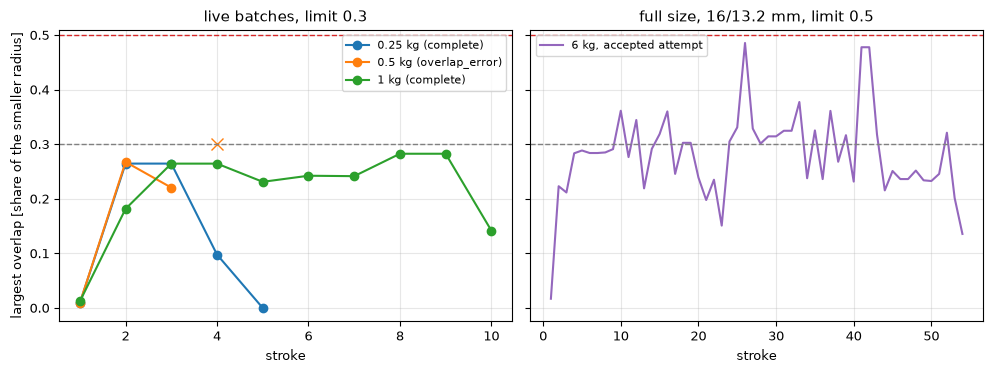

In [21]:
# Figure 3: the largest overlap of each stroke, in the live batches and in the full-size run of the same feed,
# against the two limits
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.8), sharey=True)
for batch in sorted(sweep):
    r = sweep[batch]
    strokes_r = [row["stroke"] for row in r["series"]]
    overlaps = [row["max_overlap"] for row in r["series"]]
    line = axes[0].plot(strokes_r, overlaps, "o-", label=f"{batch:g} kg ({r['status']})")
    if r["stopped_during_stroke"]:
        axes[0].plot(r["stopped_during_stroke"], r["max_overlap_reached"], "x", ms=9, color=line[0].get_color())
axes[0].set_title("live batches, limit 0.3")
full = final["16/13.2"]["series"]
axes[1].plot(full["stroke"], full["max_overlap"], "-", color="tab:purple", label="6 kg, accepted attempt")
for ax in axes:
    ax.axhline(0.3, color="gray", ls="--", lw=1)
    ax.axhline(0.5, color="tab:red", ls="--", lw=1)
    ax.set_xlabel("stroke")
    ax.legend(fontsize=8)
axes[0].set_ylabel("largest overlap [share of the smaller radius]")
axes[1].set_title("full size, 16/13.2 mm, limit 0.5")
fig.tight_layout()
plt.show()

Reading figure 3. On the left the live batches stay below 0.3 in the strokes the series records; the 0.5 kg batch ends with a cross at 0.300 in stroke 4, where it stopped, and the three curves have no common trend with the mass. On the right the full-size run does not drift upward either: its largest overlap swings from stroke to stroke across the whole range printed above, crossing the 0.3 line many times before the batch ends. The figure does not show what causes the large overlaps, a jammed bed or a local event, because the package's record does not separate them; the package's README and validation record (Santibanez-Leal, 2026) list the stiffness of the contact, six times softer than the one the paper's own calibration implies, among seven candidate causes that were not tested.

### Using it on your own data

Three things are needed: the machine, the ore and the feed. The machine is built by `crushdem.machines.jaw` with the feed opening, closed side setting, throw, plate width, nip angle and frequency, or, for the paper's jaw, by `jaw_barrios2020`, whose every dimension carries its source in `machine.provenance`; the contact table gives the materials and the restitution and friction of each pair. The ore is an `Ore` with the eight parameters of the table above, which for your rock come from single-particle compression tests: the median breakage force of at least two size classes, mapped to energy with `case.energy_at_force` and fitted with `case.fixed_phi_fit`, exactly as `paper_ore` does. The feed is a list of size classes (`SizeClass`) with a batch mass, and `machine.feed` draws the spheres with a seed. `case.build` assembles them, `case.run_attempt` runs the strokes and `comparison.window_statistics` reads the result.

The first cell takes the paper's three class medians as if they were your tests and prints the mapped energies and the misfit of the fit.

In [22]:
# Your own ore: single-particle medians to fracture energies, then a size effect (the paper's class medians stand
# in for your tests)
my_forces = {"63/53": 4831.05, "31.5/26.5": 1965.6, "16.0/13.2": 1701.95}
sizes_m = np.array([case.SIZE_CLASS_MEAN_M[k] for k in my_forces])
masses = 2700.0 * math.pi / 6.0 * sizes_m**3
energies = np.array([case.energy_at_force(f, d) for f, d in zip(my_forces.values(), sizes_m)]) / masses
e_inf, d0, residual = case.fixed_phi_fit(sizes_m, energies, ore.phi)
print(f"mapped E50 [J/kg] {np.round(energies, 1)}, E_inf = {e_inf:.2f} J/kg, d0 = {d0 * 1e3:.2f} mm")
print("misfit of each class in ln E50:", np.round(residual, 3))

mapped E50 [J/kg] [ 26.6  58.2 451.1], E_inf = 13.84 J/kg, d0 = 55.02 mm
misfit of each class in ln E50: [-0.     0.    -0.984]


The ore cell returns the mapped energies of the paper's classes, 26.6, 58.2 and 451.1 J/kg, and the fit, 13.84 J/kg and 55.02 mm, with a misfit of -0.984 on the third class: the check to make on your own tests is whether that residual is small on every class you kept in the fit, and what the extrapolation to the sizes you did not test does. The second cell runs a different jaw, a 10 mm closed side at 5 Hz, for three strokes of 0.25 kg, and prints the three things to read in any output: the status, the mass balance residual and the largest overlap, then whether the run has a window.

In [23]:
# Your own jaw: another setting and frequency through the same builder, and the three things to read in its output
with contextlib.redirect_stdout(io.StringIO()):
    mine = case.run_attempt(ore, 0.25, 5.0, 1, 800, 0.3, "numba", 3, 300.0, 40,
                            feed_class="16/13.2", closed_side_setting=0.010)
checks = comparison.window_statistics(mine["series"], 1.0 / 5.0)
print(f"status {mine['status']}; mass balance residual {mine['mass_balance_residual_kg']:.1e} kg;",
      f"largest overlap {mine['max_overlap_reached']:.3f}")
print("window:", checks["window"], "|", checks.get("reason", "found"))

status complete; mass balance residual 6.3e-17 kg; largest overlap 0.146
window: None | the run has 3 strokes, fewer than the 6 a window needs: no window


The jaw cell completes with a mass balance residual of 6.3e-17 kg, which is round-off, and a largest overlap of 0.146, well inside 0.3. Its window is absent, with the reason the package gives: the run has 3 strokes, fewer than the 6 a window needs. Three readings therefore decide whether a result is a result: the balance closes to round-off, the overlap stays under the limit for the strokes the average is taken over, and the window exists and is long enough for its error and its trend to be defined.

## Results

**Answer:** The simulation decides that a sphere breaks when the specific energy of its event, taken from the work of its contacts, reaches a fracture energy drawn once from a lognormal law whose median is 168.6 J/kg at 14.6 mm; events below it weaken the sphere by $E' = E(1-D)$, so that a sphere hit with 50.6 J/kg events breaks at the eighth. The break is replaced by pieces whose sizes follow from $t_{10}$ (5.354 percent for a 57.5 mm sphere at 100 J/kg, 0.879 for a 14.6 mm one), conserving mass to 5.1e-16 of the parent and injecting at most 4.93e-03 of the absorbed energy. The two pieces of this chain that can be checked independently match: the contact peak overlap to 173.70 against 173.69 micrometres, and the energy mapping to 2.0073 J.

The method stops working on this jaw where the overlap passes the limit that makes the contact meaningful. At 0.3 the three committed full-size runs stop, in strokes 6, 3 and 10; at 0.5 the coarse and the fine feed complete, in 83 and 54 strokes, with 33 and 23 of their strokes above 0.3, and the middle feed stops again at 0.547 in stroke 6 with 327 spheres held. Of three feeds, two give a window, with a mean plate power of 300.9 W and a standard error of 24.9 W for the coarse one, and one gives nothing to compare.

## Summary

- A sphere breaks when the energy of its event reaches its fracture energy, drawn once from a lognormal law whose median falls with size and whose width is set by $\sigma^2$; events below it add damage by $E' = E(1-D)$.
- The progeny follow from $t_{10} = A[1 - \exp(-b'\,e E_k/E_{50})]$ and the incomplete beta function, are drawn as spheres, conserve mass and are bounded in injected energy.
- A run stops when its largest overlap passes a fraction of the smaller radius, and the product's ladder tries 0.3 and then 0.5: at 0.3 all three committed full-size runs stop, at 0.5 two of the three feeds complete and the middle feed does not.
- The window of a batch is set by mass, its standard error takes the lag-1 autocorrelation of the strokes, and a window of three strokes cannot state a trend.
- Your own crusher needs a machine, an ore from single-particle tests and a feed, and three readings of the output: the mass balance, the overlap and the window.
- Notebook 03 holds the particle simulation against the measurement and against the population balance with a jaw capacity model.

## References

- Barrios, G. K., Jiménez-Herrera, N., Fuentes-Torres, S. N., Tavares, L. M. (2020). DEM simulation of laboratory-scale jaw crushing of a gold-bearing ore using a particle replacement model. Minerals 10(8), 717. https://doi.org/10.3390/min10080717
- Bayley, G. V., Hammersley, J. M. (1946). The "effective" number of independent observations in an autocorrelated time series. Supplement to the Journal of the Royal Statistical Society 8(2), 184-197. https://doi.org/10.2307/2983560
- Cleary, P. W., Sinnott, M. D. (2015). Simulation of particle flows and breakage in crushers using DEM: Part 1, Compression crushers. Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Johnson, K. L. (1985). Contact mechanics. Cambridge University Press. https://doi.org/10.1017/CBO9781139171731
- Santibanez-Leal, F. (2026). crushdem 0.6.0, package page and README, with the candidate causes of the jaw result. https://pypi.org/project/crushdem/
- Tavares, L. M. (2022). Review and further validation of a practical single-particle breakage model. KONA Powder and Particle Journal 39, 62-83. https://doi.org/10.14356/kona.2022012
- Tsuji, Y., Tanaka, T., Ishida, T. (1992). Lagrangian numerical simulation of plug flow of cohesionless particles in a horizontal pipe. Powder Technology 71(3), 239-250. https://doi.org/10.1016/0032-5910(92)88030-L
- The Rayleigh time step, as stated in the documentation of fix check/timestep/gran, https://www.cfdem.com/media/DEM/docu/fix_check_timestep_gran.html